# Health Index và ARIMA forecast trên FD001 train

**Học viên:** Phan Nguyễn Mai Phương  
**MSHV:** 25002711

Đây là phân tích chuỗi thời gian phụ, tách khỏi mô hình RUL. Health Index là thành
phần chính thứ nhất (PCA) của các sensor đã chuẩn hóa, được đổi dấu để giảm dần theo
cycle. Với 10 validation engines, phần đầu chuỗi được dùng để fit ARIMA và phần cuối
làm holdout. Notebook đọc artifact trong `outputs/timeseries/`, tính lại metric
holdout của ARIMA và hai naive baseline, rồi so với artifact. Notebook không fit
ARIMA và không ghi file.

```text
Silver observations (train) -> StandardScaler + PCA(1) -> Health Index (health_index.csv)
                                                       -> 10 validation engines: prefix | holdout
                                                             prefix -> ARIMA(p,d,q) -> forecast + khoảng dự đoán 95%
                                                             prefix -> last value, drift
```

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "outputs").is_dir():
    ROOT = ROOT.parent  # notebook được mở từ thư mục notebooks/
assert (ROOT / "outputs").is_dir(), "Chạy notebook từ thư mục gốc repository"

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})


def read_json(relative: str) -> dict:
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))

from scipy.stats import spearmanr

from cmapss.timeseries.baselines import evaluate_forecast_baselines

TS = ROOT / "outputs" / "timeseries"
health_index = pd.read_csv(TS / "tables" / "health_index.csv")
selected_engines = pd.read_csv(TS / "tables" / "selected_engines.csv")
forecast_metrics = pd.read_csv(TS / "tables" / "forecast_metrics.csv")
baseline_metrics = pd.read_csv(TS / "tables" / "baseline_metrics.csv")
diagnostics = pd.read_csv(TS / "tables" / "diagnostics.csv")
forecasts = pd.read_parquet(TS / "predictions" / "arima_forecasts.parquet")
ts_run = read_json("outputs/timeseries/run_info.json")
print("Health Index rows:", len(health_index), "| engines:", health_index["engine_id"].nunique())
print("Dùng test labels:", ts_run["isolation"]["uses_test_labels"])

%matplotlib inline

Health Index rows: 20631 | engines: 100
Dùng test labels: False


## 1. Health Index có giảm theo cycle không?

Spearman ρ giữa cycle và Health Index được tính riêng cho từng engine. Giá trị gần
−1 nghĩa là Health Index giảm gần như đơn điệu theo thời gian.

count    100.0000
mean      -0.9249
std        0.0254
min       -0.9589
25%       -0.9421
50%       -0.9315
75%       -0.9167
max       -0.8356
dtype: float64


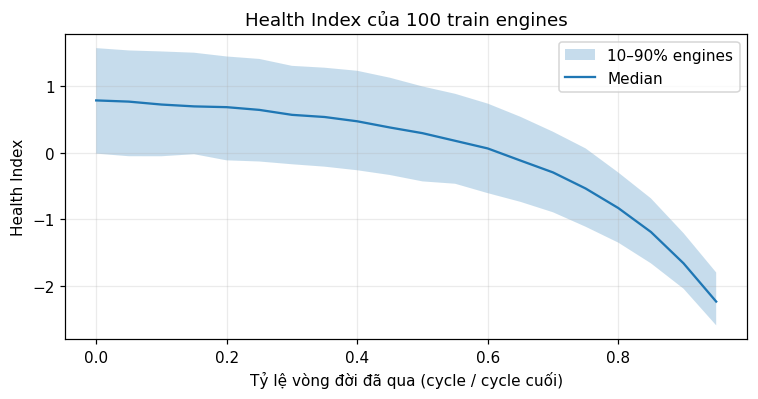

In [2]:
rho = health_index.groupby("engine_id").apply(
    lambda group: spearmanr(group["cycle"], group["health_index"]).statistic, include_groups=False
)
print(rho.describe().round(4))

lifetime = health_index.groupby("engine_id")["cycle"].transform("max")
normalized = health_index.assign(life_fraction=health_index["cycle"] / lifetime)
normalized["bin"] = (normalized["life_fraction"] * 20).clip(upper=19.999).astype(int) / 20
band = normalized.groupby("bin")["health_index"].quantile([0.1, 0.5, 0.9]).unstack()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.fill_between(band.index, band[0.1], band[0.9], alpha=0.25, label="10–90% engines")
ax.plot(band.index, band[0.5], label="Median")
ax.set(xlabel="Tỷ lệ vòng đời đã qua (cycle / cycle cuối)", ylabel="Health Index", title="Health Index của 100 train engines")
ax.legend()
plt.show()

Spearman ρ của cả 100 engines đều âm, trung vị khoảng −0.93, nên Health Index giảm
nhất quán theo cycle. Khi chuẩn hóa theo tỷ lệ vòng đời, median Health Index giảm chậm
trong khoảng 60% vòng đời đầu rồi giảm nhanh ở phần cuối. Diễn giải: holdout của ARIMA
nằm ở phần cuối chuỗi, nơi độ dốc thay đổi, nên forecast ngoại suy từ prefix có thể lệch
khỏi xu hướng thực tế.

## 2. Tính lại metric holdout của ARIMA

`arima_forecasts.parquet` lưu giá trị thật, forecast và khoảng dự đoán 95% trên
holdout. MAE, RMSE và coverage được tính lại rồi so với `forecast_metrics.csv`.
Coverage là tỷ lệ điểm holdout nằm trong khoảng dự đoán.

In [3]:
error = forecasts["health_index_pred"] - forecasts["health_index_true"]
inside = forecasts["health_index_true"].between(forecasts["lower_95"], forecasts["upper_95"])
arima_check = (
    forecasts.assign(abs_error=error.abs(), sq_error=error**2, inside=inside)
    .groupby("engine_id")
    .agg(mae=("abs_error", "mean"), rmse=("sq_error", lambda values: float(np.sqrt(values.mean()))), coverage_95=("inside", "mean"))
)
stored = forecast_metrics.set_index("engine_id").loc[arima_check.index]
for column in ("mae", "rmse", "coverage_95"):
    assert np.allclose(arima_check[column], stored[column]), column
print("Metric ARIMA khớp với forecast_metrics.csv.")
stored[["order", "n_train", "n_holdout", "mae", "rmse", "coverage_95"]]

Metric ARIMA khớp với forecast_metrics.csv.

,order,n_train,n_holdout,mae,rmse,coverage_95
engine_id,,,,,,
24,"(1, 0, 1)",102,45,0.1572,0.1897,0.9556
39,"(0, 1, 1)",89,39,0.8860,1.0788,0.3590
57,"(1, 0, 2)",95,42,0.4346,0.5230,0.5000
67,"(2, 0, 1)",219,94,0.1607,0.2018,0.9362
69,"(1, 0, 1)",253,109,0.4585,0.5645,0.5046
70,"(2, 1, 2)",95,42,1.0372,1.2205,0.2143
83,"(1, 0, 1)",205,88,0.1708,0.2171,0.8750
91,"(1, 0, 1)",94,41,0.4900,0.6422,0.4878
92,"(1, 0, 1)",238,103,0.1631,0.2066,0.8932


## 3. ARIMA so với naive baseline

Hai baseline dùng cùng điểm cắt với ARIMA: `last_value` giữ nguyên giá trị cuối của
prefix, `drift` ngoại suy độ dốc trung bình từ điểm đầu tới điểm cuối của prefix.
Baseline được tính lại từ Health Index bằng `evaluate_forecast_baselines`.

In [4]:
rows = []
for record in forecast_metrics.itertuples():
    series = health_index.loc[health_index["engine_id"].eq(record.engine_id)].sort_values("cycle")["health_index"].to_numpy()
    fit, holdout = series[: record.n_train], series[record.n_train : record.n_train + record.n_holdout]
    for name, scores in evaluate_forecast_baselines(fit, holdout).items():
        rows.append({"engine_id": record.engine_id, "baseline_name": name, "mae": scores["mae"], "rmse": scores["rmse"]})
baseline_check = pd.DataFrame(rows).set_index(["engine_id", "baseline_name"]).sort_index()
stored_baselines = baseline_metrics.set_index(["engine_id", "baseline_name"]).sort_index()
assert np.allclose(baseline_check[["mae", "rmse"]], stored_baselines[["mae", "rmse"]])
print("Baseline khớp với baseline_metrics.csv.")

comparison = baseline_check["mae"].unstack().join(stored["mae"].rename("arima"))
comparison["arima_best"] = comparison["arima"] < comparison[["last_value", "drift"]].min(axis=1)
print("ARIMA có MAE thấp nhất ở", int(comparison["arima_best"].sum()), "/", len(comparison), "engines")
comparison.round(4)

Baseline khớp với baseline_metrics.csv.
ARIMA có MAE thấp nhất ở 7 / 10 engines


,drift,last_value,arima,arima_best
engine_id,,,,
24,0.9198,1.1567,0.1572,True
39,0.7108,0.8701,0.8860,False
57,1.5685,1.6304,0.4346,True
67,0.4567,0.7095,0.1607,True
69,0.5023,0.7813,0.4585,True
70,0.7990,0.9586,1.0372,False
83,1.0064,1.2305,0.1708,True
91,0.3286,0.5289,0.4900,False
92,0.5105,0.6991,0.1631,True


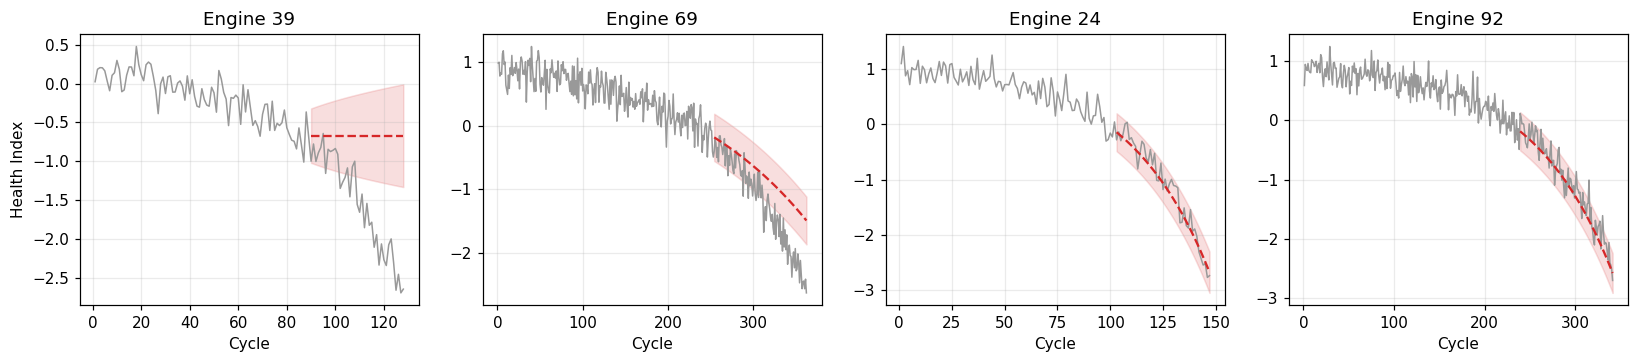

In [5]:
engines = forecast_metrics["engine_id"].tolist()[:4]
fig, axes = plt.subplots(1, len(engines), figsize=(15, 3.4), sharey=False)
for ax, engine_id in zip(axes, engines):
    history = health_index.loc[health_index["engine_id"].eq(engine_id)]
    forecast = forecasts.loc[forecasts["engine_id"].eq(engine_id)]
    ax.plot(history["cycle"], history["health_index"], color="0.6", linewidth=1)
    ax.plot(forecast["cycle"], forecast["health_index_pred"], color="tab:red", linestyle="--")
    ax.fill_between(forecast["cycle"], forecast["lower_95"], forecast["upper_95"], color="tab:red", alpha=0.15)
    ax.set(title=f"Engine {engine_id}", xlabel="Cycle")
axes[0].set_ylabel("Health Index")
plt.tight_layout()
plt.show()

ARIMA có MAE thấp hơn cả hai baseline ở 7/10 validation engines. Trung bình coverage
của khoảng dự đoán 95% chỉ khoảng 0.67, thấp hơn mức danh nghĩa 0.95. Coverage thấp nhất
ở engine 70 (0.21) và 39 (0.36). Ở engine 39 (hình trên), forecast gần như đi ngang trong
khi holdout giảm mạnh, nên phần lớn điểm holdout nằm ngoài khoảng dự đoán.

## 4. Diagnostics của chuỗi fit

- ADF test: p-value lớn nghĩa là không bác bỏ giả thuyết có unit root; chuỗi prefix
  không dừng, phù hợp với xu hướng giảm.
- Ljung–Box trên residual: p-value nhỏ (< 0.05) cho thấy residual còn tự tương quan,
  tức model chưa nắm hết cấu trúc chuỗi.

In [6]:
table = diagnostics[["engine_id", "order", "adf_pvalue", "ljung_box_pvalue", "fit_converged"]].copy()
table["residual_autocorrelated_5pct"] = table["ljung_box_pvalue"] < 0.05
table.sort_values("engine_id")

,engine_id,order,adf_pvalue,ljung_box_pvalue,fit_converged,residual_autocorrelated_5pct
2,24,"(1, 0, 1)",0.9990,0.0956,True,False
0,39,"(0, 1, 1)",0.8606,0.8144,True,False
8,57,"(1, 0, 2)",0.9966,0.5112,True,False
7,67,"(2, 0, 1)",0.9836,0.7493,True,False
1,69,"(1, 0, 1)",0.9917,0.0313,True,True
6,70,"(2, 1, 2)",0.9811,0.0269,True,True
9,83,"(1, 0, 1)",0.9985,0.4331,True,False
4,91,"(1, 0, 1)",0.9968,1.0000,True,False
3,92,"(1, 0, 1)",0.9989,0.4386,True,False
5,96,"(1, 0, 1)",0.9939,0.4962,True,False


## Tóm tắt

- Metric ARIMA và hai baseline tính lại đều khớp với artifact.
- Health Index giảm nhất quán theo cycle trên toàn bộ 100 train engines.
- ARIMA thường tốt hơn naive baseline về MAE, nhưng khoảng dự đoán 95% thiếu coverage.
  Residual của engine 69 và 70 còn tự tương quan ở mức 5%.
- Health Index forecast không phải dự đoán RUL và không được dùng để suy ra lịch bảo trì.